<a href="https://colab.research.google.com/github/tanush-2008/IIITH-Collab-Notebooks/blob/main/AIML_Module_03_Lab_01_Reviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Module 3
## Lab 1: Gradient Descent

# Gradient Descent: A Quick Recap

We introduced **Gradient Descent** as a method to find the minimum of a loss function. It is the core optimization algorithm that powers a vast majority of **Machine Learning** and **Deep Learning** models.

---

### A Quick Recap of the Algorithm

The core idea of **Gradient Descent** is to iteratively take steps in the direction of the steepest descent of a function (our loss function) to find its minimum.

1. Start with a random initialization of the solution (model parameters or weights).
2. Incrementally change the solution by moving in the direction of the **negative gradient** of the loss function.
3. Repeat the previous step until some convergence criteria is met.

---

The key update equation for a weight or parameter ($w$) is:

$$
w_{k+1} \leftarrow w_k - \eta \nabla J
$$

Where:
- $w_k$ is the current weight.
- $\eta$ is the **learning rate**.
- $\nabla J$ is the **gradient of the loss function** $J$.


In this lab, we will discuss stochastic gradient descent, mini-batch gradient descent and batch gradient descent.


### Setting up the Environment and Data

First, let's import the necessary libraries and set a random seed for reproducibility.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

## Creating the Data

We'll generate some synthetic data that follows a **linear pattern**. Our true linear equation will be:

$$
y = 4 + 3x
$$

We will also add some **random noise** to the y values to simulate real-world data, which is rarely perfect.

Let's generate the data with:
- `y0 = 4` (intercept)
- `y1 = 3` (slope)

and add some noise to the data.


In [ ]:
# We are creating data based on the equation y = 4 + 3x + noise

X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

Here, np.random.rand(100, 1) creates 100 random numbers between 0 and 1. Multiplying by 2 scales this to be between 0 and 2. np.random.randn(100, 1) adds Gaussian noise (random fluctuations) to our y values.

Let's also plot the data we just created

Text(0, 0.5, 'y')

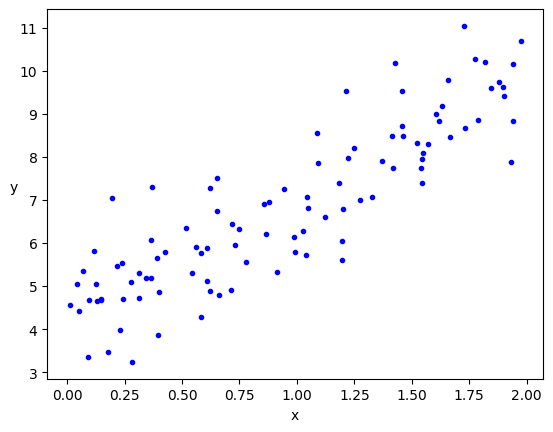

In [ ]:
plt.plot(X, y, 'b.')
plt.xlabel('x')
plt.ylabel('y', rotation=0)

Our goal is to use Gradient Descent to find the original parameters (intercept = 4, slope = 3) just by looking at this scattered data.

## The Cost Function for Linear Regression

Before we can optimize, we need to define how we measure error. For **Linear Regression**, we use the **Mean Squared Error (MSE)** cost function. It measures the average squared difference between the model's predictions and the actual values.

The equation for the MSE cost function $J$ is:

$$
J(\theta) = \frac{1}{2m}  \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)^2
$$

Where:
- $m$ is the number of training examples.
- $\theta$ is our vector of model parameters (in our case, the intercept and the slope).
- $h_\theta(x^{(i)})$ is the prediction for the $i$-th example.
- $y^{(i)}$ is the true label for the $i$-th example.

The $\frac{1}{2}$ is included for convenience, as it simplifies the derivative calculation.


In [ ]:
def cal_cost(y_pred, X, y):
    '''
    Calculates the cost for given X and Y.
    y_pred = Vector of y_preds
    X = Row of X's np.zeros((2, j))
    y = Actual y's np.zeros((2, 1))

    where:
        j is the no of features
    '''

    m = len(y)

    predictions = X.dot(y_pred)
    cost = (1 / 2 * m) * np.sum(np.square(predictions - y))

    return cost

## The Gradient of the Cost Function

To use **Gradient Descent**, we need the partial derivatives of the cost function with respect to each parameter \(\theta_j\).

The general form of the gradient for **Linear Regression** is:

$$
\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) x_j^{(i)}
$$

For our problem with one feature \(x\) and an intercept, we have two parameters: \(\theta_0\) (intercept) and \(\theta_1\) (slope). The updates will be:

$$
\theta_0 := \theta_0 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right)
$$

$$
\theta_1 := \theta_1 - \alpha \cdot \frac{1}{m} \sum_{i=1}^{m} \left( h_\theta(x^{(i)}) - y^{(i)} \right) \cdot x_1^{(i)}
$$

This can be written in a compact, **vectorized form**:

$$
\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)
$$


### Variant 1: Batch Gradient Descent

**Batch Gradient Descent** is the simplest variant. In each step, it calculates the gradient using the **entire training dataset**.

**Pros:**
- The convergence path is smooth and stable because the gradient is a true average over all data.

**Cons:**
- It is very slow and computationally expensive for large datasets.


In [ ]:
def gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=100):
    '''
    X = Matrix of X with added bias units
    y = Vector of Y
    y_pred = Vector of parameters (theta)
    learning_rate
    iterations = no of iterations

    Returns the final y_pred vector and array of cost history over no of iterations
    '''
    m = len(y)
    cost_history = np.zeros(iterations)
    y_pred_history = np.zeros((iterations, 2))

    for it in range(iterations):
        # Calculate prediction: prediction = X . theta
        prediction = np.dot(X, y_pred)

        # Update parameters: theta = theta - (1/m) * learning_rate * (X^T . (prediction - y))
        y_pred = y_pred - (1 / m) * learning_rate * (X.T.dot((prediction - y)))

        y_pred_history[it,:] = y_pred.T
        cost_history[it]  = cal_cost(y_pred, X, y)

    return y_pred, cost_history, y_pred_history

### Running Batch Gradient Descent

Let's run this for **1000 iterations** with a learning rate of **0.01**. We start with a random guess for our parameters (`y_pred`).

**Our model** is:
$$
y = \theta_0 + \theta_1 x
$$

**A crucial step:**
To handle the intercept term $\theta_0$ using matrix multiplication, we add a "dummy" feature $x_0 = 1$ to all our input samples. This is known as the **bias trick**.


In [ ]:
lr = 0.01
n_iter = 1000

y_pred = np.random.randn(2,1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history, y_pred_history = gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 3.903
y_pred[1]: 3.046
Final error: 4180.375


The learned parameters (3.903, 3.046) are very close to our original true values (4, 3)!

### Visualizing the Loss

Let's plot the error at each iteration. This is our "descent down the mountain".

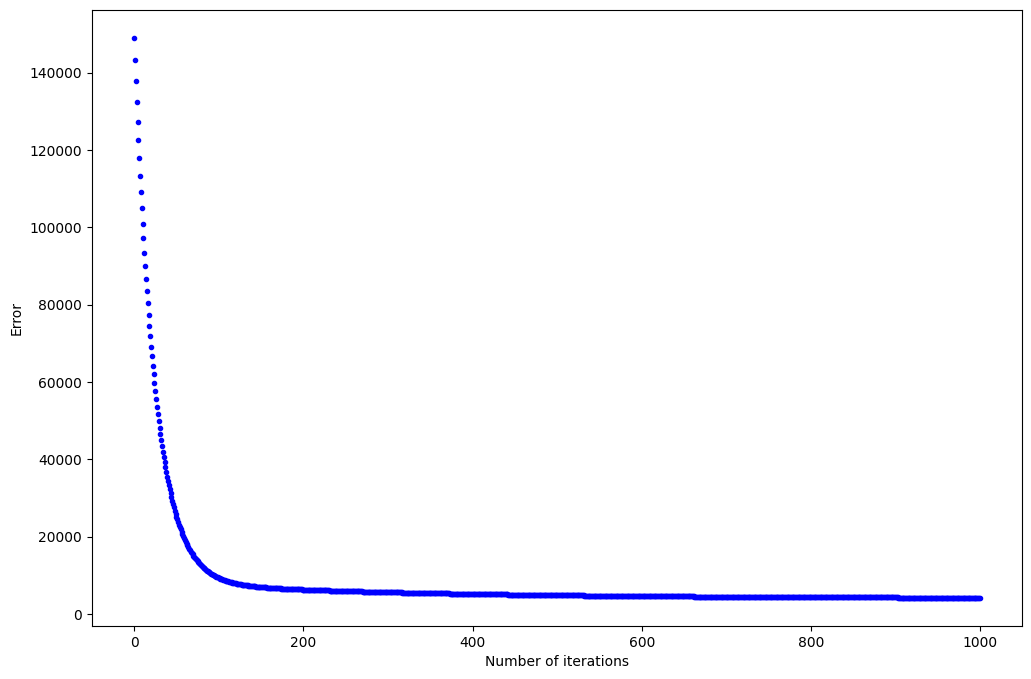

In [ ]:
fig, ax = plt.subplots(figsize=(12,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')

ax.plot(range(n_iter), cost_history, 'b.')

Zooming in on the first 200 iterations shows how the error drops rapidly at first and then slows down as it approaches the minimum.

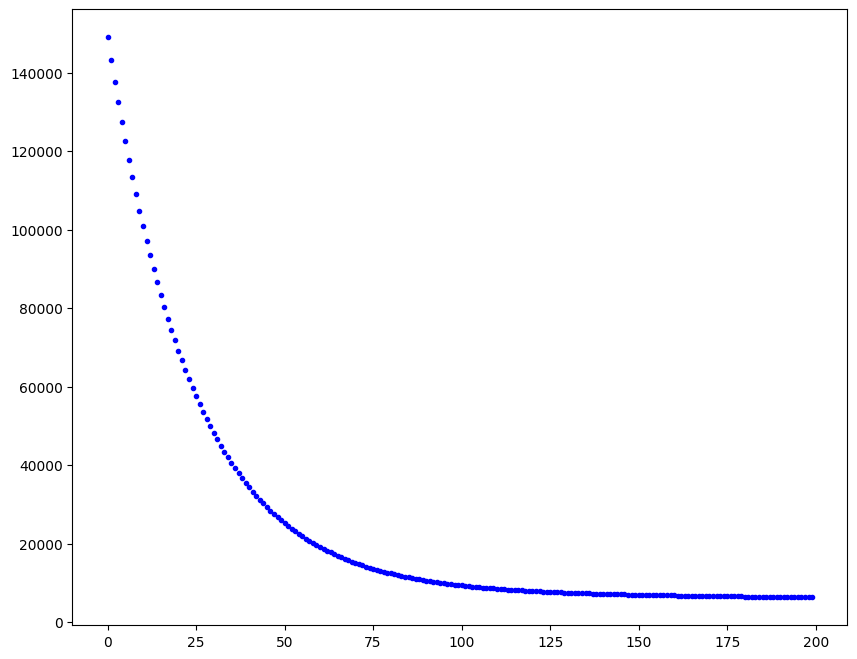

In [ ]:
fig,ax = plt.subplots(figsize=(10,8))
ax.plot(range(200), cost_history[:200], 'b.')

The smooth curve is characteristic of Batch Gradient Descent.

### Variant 2: Stochastic Gradient Descent (SGD)

**Batch GD** is inefficient for large datasets. **SGD** addresses this by taking a gradient step based on **only one randomly chosen training example at a time**.

**Pros:**
- Extremely fast per step.
- Can help escape shallow local minima due to its random nature.

**Cons:**
- The path to the minimum is very noisy and erratic.
- It never truly "settles" at the minimum but bounces around it.


In [ ]:
def stocashtic_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10):
    '''
    X = Matrix of X with added bias units
    y = Vector of Y
    y_pred = Vector of y_pred np.random.randn(j,1)
    learning_rate
    iterations = no of iterations

    Returns the final y_pred vector and array of cost history over no of iterations
    '''

    m = len(y)
    cost_history = np.zeros(iterations)

    for it in range(iterations):
        cost = 0.0

        for i in range(m):
            rand_ind = np.random.randint(0,m)
            X_i = X[rand_ind, :].reshape(1, X.shape[1])
            y_i = y[rand_ind].reshape(1,1)
            prediction = np.dot(X_i, y_pred)

            y_pred = y_pred - (1 / m) * learning_rate *(X_i.T.dot((prediction - y_i)))
            cost += cal_cost(y_pred, X_i, y_i)

        cost_history[it]  = cost

    return y_pred, cost_history

Let's run SGD. Note that it requires a much higher learning rate and fewer epochs (passes over the data) to converge.

In [ ]:
lr = 0.5
n_iter = 50
y_pred = np.random.randn(2, 1)
X_b = np.c_[np.ones((len(X), 1)), X]
y_pred, cost_history = stocashtic_gradient_descent(X_b, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.121
y_pred[1]: 2.755
Final error: 41.313


Again, the parameters are close to the true values, but notice the final error is higher and the parameters are slightly less accurate. This is due to the noisy nature of SGD.


### Visualizing the Loss

The loss curve for SGD is much more erratic.

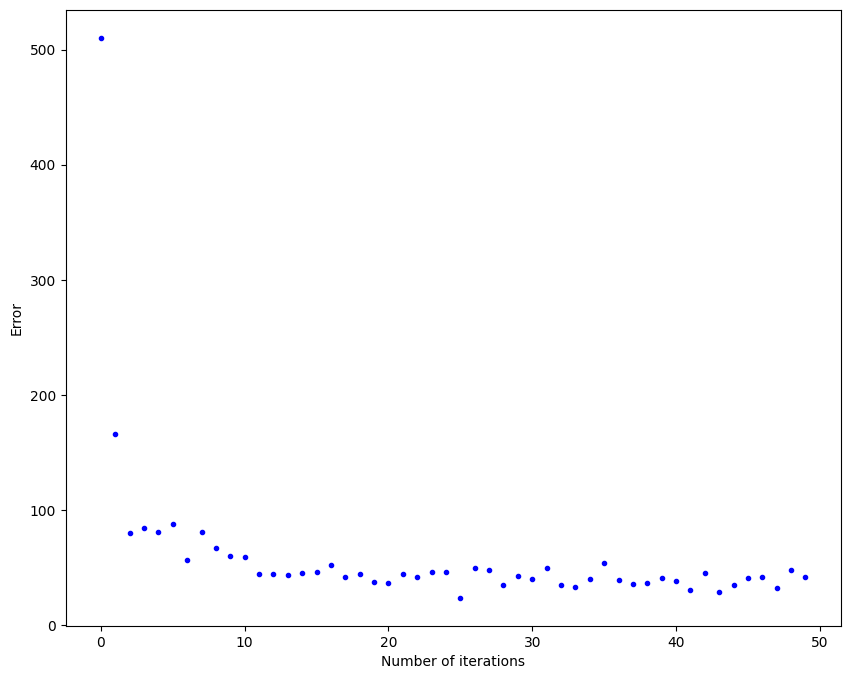

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Variant 3: Mini-Batch Gradient Descent

**Mini-Batch GD** is the happy medium. It computes the gradient on a small, random subset of the data called a **mini-batch**.

**Pros:**
- A good balance between the stability of Batch GD and the speed of SGD.
- Allows for vectorized implementation, making it very efficient on modern hardware (like GPUs).

**Cons:**
- Introduces a new hyperparameter: the `batch_size`.

This is the **most common variant** used in deep learning today.


In [ ]:
def minibatch_gradient_descent(X, y, y_pred, learning_rate=0.01, iterations=10, batch_size=20):
    '''
    X = Matrix of X without added bias units
    y = Vector of Y
    y_pred = Vector of y_preds np.random.randn(j, 1)
    learning_rate
    iterations = no of iterations

    Returns the final theta vector and array of cost history over no of iterations
    '''

    m = len(y)
    cost_history = np.zeros(iterations)
    n_batches = int(m / batch_size)

    for it in range(iterations):
        cost = 0.0
        indices = np.random.permutation(m)
        X = X[indices]
        y = y[indices]

        for i in range(0, m, batch_size):
            X_i = X[i: i + batch_size]
            y_i = y[i: i + batch_size]

            X_i = np.c_[np.ones(len(X_i)), X_i]
            prediction = np.dot(X_i, y_pred)

            y_pred = y_pred - (1 / m) * learning_rate * (X_i.T.dot((prediction - y_i)))
            cost += cal_cost(y_pred, X_i, y_i)

        cost_history[it]  = cost

    return y_pred, cost_history

Let's run it.

In [ ]:
lr = 0.1
n_iter = 200
y_pred = np.random.randn(2,1)
y_pred, cost_history = minibatch_gradient_descent(X, y, y_pred, lr, n_iter)

print('y_pred[0]: {:0.3f}\ny_pred[1]: {:0.3f}'.format(y_pred[0][0], y_pred[1][0]))
print('Final error: {:0.3f}'.format(cost_history[-1]))

y_pred[0]: 4.148
y_pred[1]: 2.827
Final error: 807.488


### Visualizing the Loss

The loss curve is less noisy than SGD but not as smooth as Batch GD.

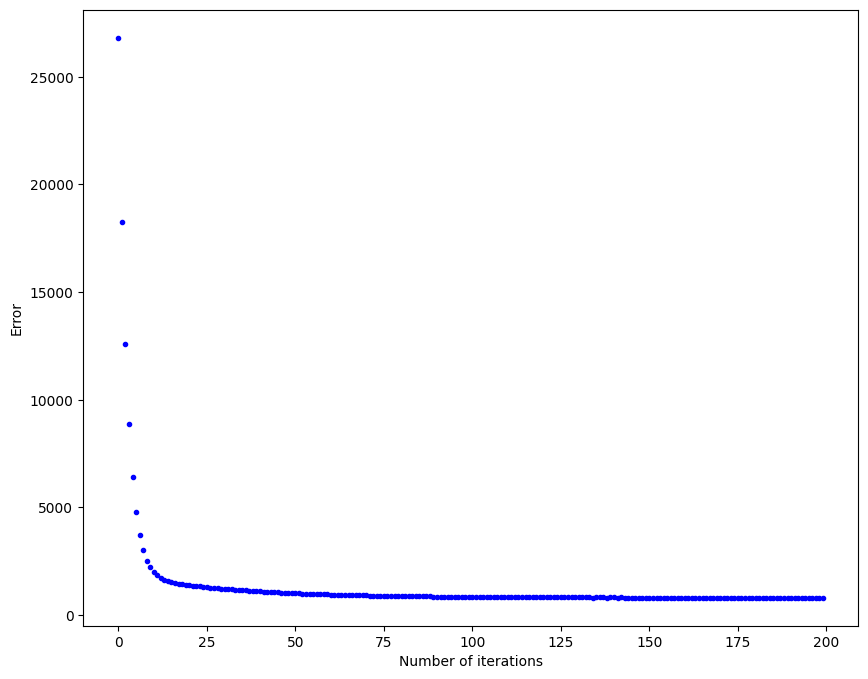

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))

ax.set_ylabel('Error')
ax.set_xlabel('Number of iterations')
y_pred = np.random.randn(2,1)

ax.plot(range(n_iter), cost_history, 'b.')

### Visual Comparison of the Learned Models

Let's re-run all three algorithms and plot their final learned lines on the original data. This will give us a better intuition for how they perform.

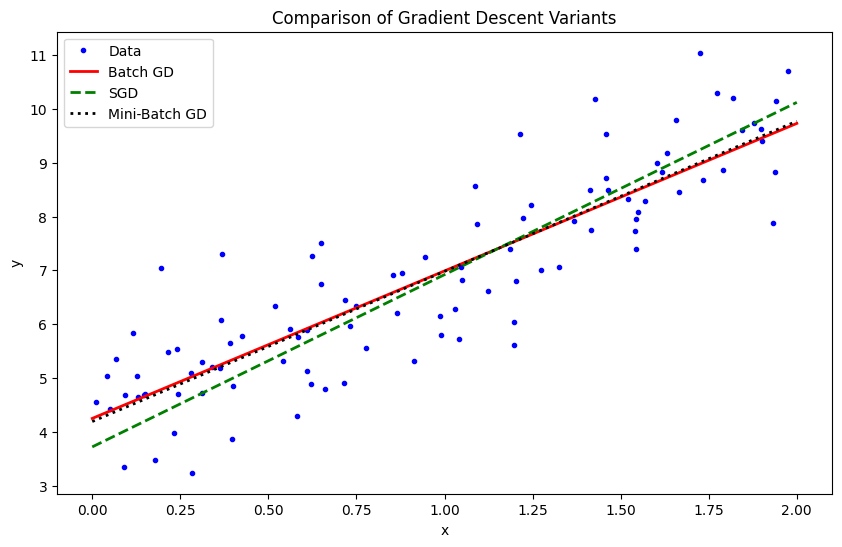

In [ ]:
# Rerun all three for comparison
# Batch
lr_batch = 0.1
n_iter_batch = 200
y_pred_batch_final, _, _ = gradient_descent(X_b, y, np.random.randn(2,1), lr_batch, n_iter_batch)

# SGD
lr_sgd = 0.05
n_iter_sgd = 200
y_pred_sgd_final, _ = stocashtic_gradient_descent(X_b, y, np.random.randn(2,1), lr_sgd, n_iter_sgd)

# Mini-Batch
lr_mini = 0.1
n_iter_mini = 200
y_pred_mini_final, _ = minibatch_gradient_descent(X, y, np.random.randn(2,1), lr_mini, n_iter_mini)


# Plotting
plt.figure(figsize=(10, 6))
plt.plot(X, y, 'b.', label='Data')
# Create a set of X values for plotting the lines
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
# Get predictions for the lines
y_predict_batch = X_new_b.dot(y_pred_batch_final)
y_predict_sgd = X_new_b.dot(y_pred_sgd_final)
y_predict_mini = X_new_b.dot(y_pred_mini_final)

plt.plot(X_new, y_predict_batch, 'r-', linewidth=2, label='Batch GD')
plt.plot(X_new, y_predict_sgd, 'g--', linewidth=2, label='SGD')
plt.plot(X_new, y_predict_mini, 'k:', linewidth=2, label='Mini-Batch GD')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparison of Gradient Descent Variants')
plt.legend()
plt.show()

As you can see, all three methods find a very good fit to the data. While their training dynamics (the loss curves) are very different, they all achieve the same goal.

### Things to Try Out

1. **Change batch size in mini-batch gradient descent:**
   Try a small size (e.g., `2`) and a large size (e.g., `80`). How does the loss curve change? What happens when the batch size equals the total number of samples?

2. **Test on real datasets:**
   Use a dataset from `sklearn.datasets`, like the **Boston Housing** or **Diabetes** datasets, and see how each variant performs.

3. **Compare learning rates:**
   Test the effects of changing the learning rate. Try a very high and a very low learning rate for each of the three variants. Which one is most sensitive to the learning rate?

4. **Implement a learning rate schedule for SGD:**
   Instead of a fixed learning rate, make it decrease over time (e.g., `lr = initial_lr / (epoch + 1)`). How does this affect the final error and the stability of the loss curve?


### Student work — Things to Try Out

The experiments below are **additional student cells**. All faculty-provided explanations and code above and below this section have been retained without edits. The existing gradient-descent functions are invoked as supplied; their implementations are not replaced or modified.


batch=  2, final MSE=0.8166, coefficients=[4.0343 2.9323]
batch= 20, final MSE=0.8165, coefficients=[4.0347 2.9317]
batch= 80, final MSE=0.8164, coefficients=[4.0346 2.9297]
batch=100, final MSE=0.8163, coefficients=[4.0356 2.9286]


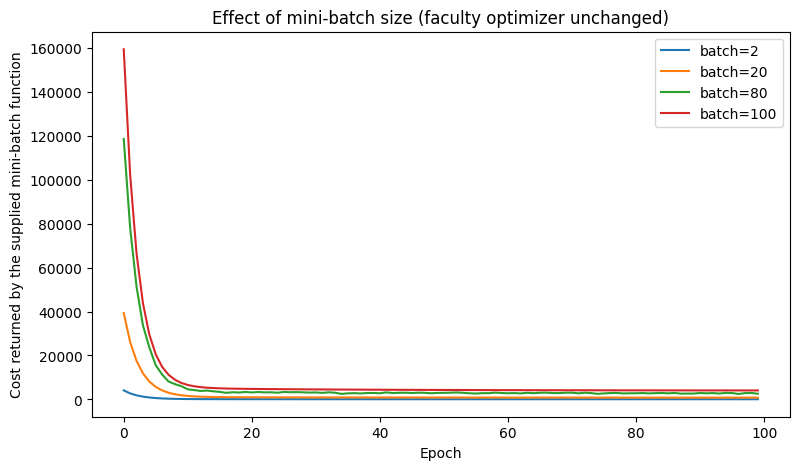

In [ ]:
# Student Experiment 1: compare the supplied mini-batch optimizer at different batch sizes.
# The original faculty functions and dataset are used unchanged.
student_batch_sizes = [2, 20, 80, len(X)]
student_batch_history = {}
student_batch_mse = {}
student_start = np.array([[0.0], [0.0]])
student_X_b = np.c_[np.ones((len(X), 1)), X]

for student_size in student_batch_sizes:
    np.random.seed(42)  # Repeatable, independent run for each batch size
    student_theta, student_hist = minibatch_gradient_descent(
        X.copy(), y.copy(), student_start.copy(),
        learning_rate=0.1, iterations=100, batch_size=student_size
    )
    student_batch_history[student_size] = student_hist
    student_batch_mse[student_size] = float(np.mean((student_X_b @ student_theta - y) ** 2))
    print(f"batch={student_size:3d}, final MSE={student_batch_mse[student_size]:.4f}, "
          f"coefficients={student_theta.ravel().round(4)}")

plt.figure(figsize=(9, 5))
for student_size, student_hist in student_batch_history.items():
    plt.plot(student_hist, label=f"batch={student_size}")
plt.xlabel('Epoch')
plt.ylabel('Cost returned by the supplied mini-batch function')
plt.title('Effect of mini-batch size (faculty optimizer unchanged)')
plt.legend()
plt.show()


**Student answer (Experiment 1):** A batch size of `2` performs many small parameter updates per epoch and may have a more variable path; a batch size of `80` uses fewer, larger batches. If `batch_size == len(X)`, the algorithm uses **one full-data update per epoch**. The graph displays the original function's reported cost, while the printed **mean squared error (MSE)** is independently computed from predictions so that end results are comparable across batch sizes. Note that batch size changes the number of updates at fixed epochs, so equal epoch counts do not imply equal computation.


In [ ]:
# Student Experiment 2: use the Diabetes dataset supplied by sklearn.
# One standardized feature (BMI) is used because the faculty example has two parameters.
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler

student_diabetes = load_diabetes()
student_real_X = StandardScaler().fit_transform(student_diabetes.data[:, [2]])
student_real_y = StandardScaler().fit_transform(student_diabetes.target.reshape(-1, 1))
student_real_X_b = np.c_[np.ones((len(student_real_X), 1)), student_real_X]
student_start = np.zeros((2, 1))

np.random.seed(42)
student_batch_theta, student_batch_hist, _ = gradient_descent(
    student_real_X_b, student_real_y, student_start.copy(), 0.05, 100
)
np.random.seed(42)
student_sgd_theta, student_sgd_hist = stocashtic_gradient_descent(
    student_real_X_b, student_real_y, student_start.copy(), 0.05, 100
)
np.random.seed(42)
student_mini_theta, student_mini_hist = minibatch_gradient_descent(
    student_real_X.copy(), student_real_y.copy(), student_start.copy(), 0.05, 100, 20
)

for student_label, student_theta in [
    ('Batch GD', student_batch_theta),
    ('Stochastic GD', student_sgd_theta),
    ('Mini-batch GD', student_mini_theta),
]:
    student_mse = np.mean((student_real_X_b @ student_theta - student_real_y)**2)
    print(f'{student_label:15s}: in-sample MSE={student_mse:.4f}; '
          f'theta={student_theta.ravel().round(4)}')


Batch GD       : in-sample MSE=0.6561; theta=[-0.     0.583]
Stochastic GD  : in-sample MSE=0.6561; theta=[-0.0007  0.5838]
Mini-batch GD  : in-sample MSE=0.6561; theta=[-1.000e-04  5.826e-01]


**Student answer (Experiment 2):** The `sklearn.datasets.load_diabetes()` dataset is a real-world regression example. We used the BMI feature and standardized the input and target so the same faculty routines can operate on it. Batch, stochastic, and mini-batch approaches can all be compared by the printed MSE and fitted coefficients. This is an **in-sample demonstration** (not a held-out generalization test); performance also depends on the number of updates and learning-rate selection.


Batch      | learning rate=0.001  | final MSE=36.229
Stochastic | learning rate=0.001  | final MSE=36.202
Mini-batch | learning rate=0.001  | final MSE=36.238
Batch      | learning rate=0.050  | final MSE=0.88294
Stochastic | learning rate=0.050  | final MSE=0.89033
Mini-batch | learning rate=0.050  | final MSE=0.88328
Batch      | learning rate=0.500  | final MSE=0.80658
Stochastic | learning rate=0.500  | final MSE=0.80702
Mini-batch | learning rate=0.500  | final MSE=0.80674
Batch      | learning rate=1.000  | final MSE=1.167e+06
Stochastic | learning rate=1.000  | final MSE=0.80672
Mini-batch | learning rate=1.000  | final MSE=0.80809


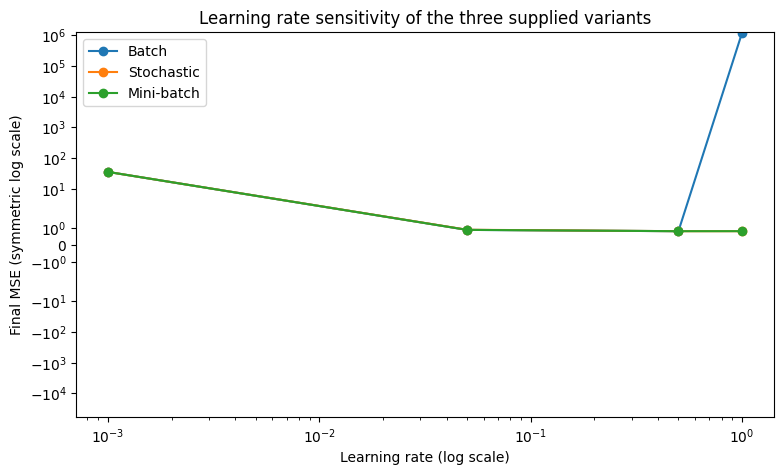

In [ ]:
# Student Experiment 3: compare low/moderate/high rates across ALL three faculty variants.
# Comparing final prediction MSE avoids mixing cost-history definitions from different routines.
student_rates = [0.001, 0.05, 0.5, 1.0]
student_synthetic_X_b = np.c_[np.ones((len(X), 1)), X]
student_start = np.zeros((2, 1))
student_final_mse = {'Batch': [], 'Stochastic': [], 'Mini-batch': []}

for student_lr in student_rates:
    np.random.seed(42)
    batch_theta, _, _ = gradient_descent(student_synthetic_X_b, y, student_start.copy(), student_lr, 80)
    np.random.seed(42)
    sgd_theta, _ = stocashtic_gradient_descent(student_synthetic_X_b, y, student_start.copy(), student_lr, 80)
    np.random.seed(42)
    mini_theta, _ = minibatch_gradient_descent(X.copy(), y.copy(), student_start.copy(), student_lr, 80, 20)
    for method, theta in [('Batch', batch_theta), ('Stochastic', sgd_theta), ('Mini-batch', mini_theta)]:
        mse = float(np.mean((student_synthetic_X_b @ theta - y)**2))
        student_final_mse[method].append(mse)
        print(f'{method:10s} | learning rate={student_lr:<6.3f} | final MSE={mse:.5g}')

plt.figure(figsize=(9, 5))
for method, errors in student_final_mse.items():
    plt.plot(student_rates, errors, 'o-', label=method)
plt.xscale('log')
plt.yscale('symlog')
plt.xlabel('Learning rate (log scale)')
plt.ylabel('Final MSE (symmetric log scale)')
plt.title('Learning rate sensitivity of the three supplied variants')
plt.legend()
plt.show()


**Student answer (Experiment 3):** With a very small learning rate, the algorithms may improve slowly within the fixed iteration limit. Large rates can make the **batch** update unstable on these features, while the stochastic/mini-batch routines may behave differently because the faculty implementations scale each per-sample or mini-batch update by the total number of examples. Inspect the actual printed MSE values rather than assuming a universal winner. For this specific notebook, **Batch GD is the most visibly sensitive to the largest trial learning rate**.


Fixed               : final MSE=0.80821; theta=[4.1826 2.7622]
Decay 1/(epoch+1)   : final MSE=0.97141; theta=[3.4583 3.3893]


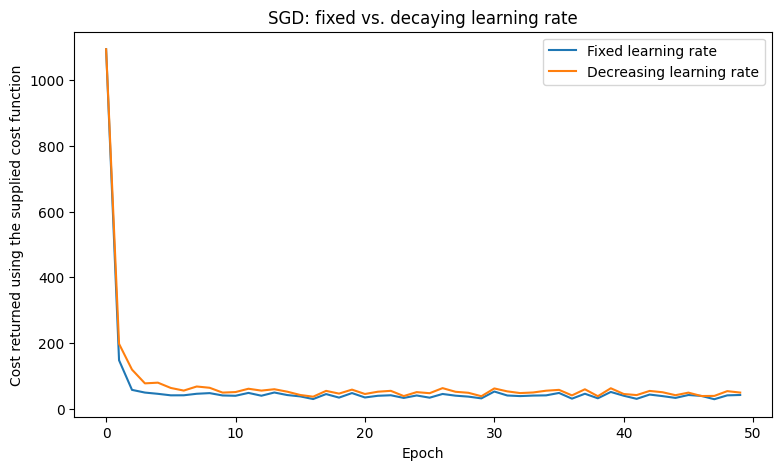

In [ ]:
# Student Experiment 4: implement a decaying learning-rate schedule for SGD.
# New student function ONLY; the faculty's SGD definition is not modified.
def student_sgd_with_schedule(X_data, y_data, theta_initial, initial_lr=0.5, epochs=50):
    theta = theta_initial.copy()
    m = len(y_data)
    epoch_costs = []
    for epoch in range(epochs):
        lr_now = initial_lr / (epoch + 1)
        total_cost = 0.0
        for _ in range(m):
            idx = np.random.randint(0, m)
            X_i = X_data[idx:idx + 1]
            y_i = y_data[idx:idx + 1]
            prediction = X_i @ theta
            # Student implementation uses the same sample update rule as the original function.
            theta = theta - (1 / m) * lr_now * X_i.T @ (prediction - y_i)
            total_cost += cal_cost(theta, X_i, y_i)
        epoch_costs.append(total_cost)
    return theta, np.asarray(epoch_costs)

np.random.seed(42)
student_fixed_theta, student_fixed_cost = stocashtic_gradient_descent(
    student_synthetic_X_b, y, np.zeros((2, 1)), learning_rate=0.5, iterations=50
)
np.random.seed(42)
student_decay_theta, student_decay_cost = student_sgd_with_schedule(
    student_synthetic_X_b, y, np.zeros((2, 1)), initial_lr=0.5, epochs=50
)
for student_label, student_theta in [('Fixed', student_fixed_theta), ('Decay 1/(epoch+1)', student_decay_theta)]:
    student_mse = np.mean((student_synthetic_X_b @ student_theta - y)**2)
    print(f'{student_label:20s}: final MSE={student_mse:.5f}; theta={student_theta.ravel().round(4)}')

plt.figure(figsize=(9, 5))
plt.plot(student_fixed_cost, label='Fixed learning rate')
plt.plot(student_decay_cost, label='Decreasing learning rate')
plt.xlabel('Epoch')
plt.ylabel('Cost returned using the supplied cost function')
plt.title('SGD: fixed vs. decaying learning rate')
plt.legend()
plt.show()


**Student answer (Experiment 4):** The step size is `initial_lr / (epoch + 1)`. This generally reduces late-stage parameter fluctuations, but it also means smaller later updates. Consequently, a decaying schedule is **not guaranteed to have a lower error in a fixed number of epochs**. Use the printed final MSE values and plotted cost trajectories to assess this experiment. All original faculty code and its answer to the critical-thinking question are unchanged.


## **Additional Critical Thinking Question**



**Which of the following is TRUE, given the optimal learning rate?**

 (i) Batch gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (ii) Stochastic gradient descent is always guaranteed to converge to the global optimum of a loss function.

 (iii) For convex loss functions (i.e. with a bowl shape), batch gradient descent is guaranteed to eventually converge to the global optimum while stochastic gradient descent is not.

 (iv) For convex loss functions (i.e. with a bowl shape), stochastic gradient descent is guaranteed to eventually converge to the global optimum while batch gradient descent is not.

 (v) For convex loss functions (i.e. with a bowl shape), both stochastic gradient descent and batch gradient descent will eventually converge to the global optimum.

 (vi) For convex loss functions (i.e. with a bowl shape), neither stochastic gradient descent nor batch gradient descent are guaranteed to converge to the global optimum.

### Answer



The correct statement is (iii).

**Explanation:**

* A convex loss function has a single minimum, which is the global minimum (like a perfect bowl).

* Batch Gradient Descent calculates the true gradient of the entire dataset. With a suitable learning rate, it will take determined, non-random steps directly towards the minimum. It is therefore guaranteed to converge to the global optimum of a convex function.

* Stochastic Gradient Descent uses a single random point to estimate the gradient. This estimate is noisy and does not point directly at the minimum. Because of this randomness, SGD will not converge to the exact minimum point but will instead perpetually bounce around in the vicinity of the minimum. To make it converge, one typically has to use a learning rate schedule that slowly decreases the learning rate to zero.

* Statements (i) and (ii) are too strong; they don't specify the type of loss function. For a non-convex function (with many local minima), neither is guaranteed to find the global optimum. They might get stuck in a local minimum.

* **Therefore**, for a convex problem, Batch GD is guaranteed to find the optimum, while standard SGD is not guaranteed to land precisely on it.